# SMS Spam Collection — Sections 4–6

Run **all cells** in order from the project root. The raw text is preserved alongside `cleaned_text`. Generated files appear in `figures/`, `outputs/` and `cleaned_data.csv`.

## Imports and setup

In [6]:
from pathlib import Path
import re, collections, warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix, ConfusionMatrixDisplay, silhouette_score, adjusted_rand_score
from sklearn.cluster import MiniBatchKMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer
ROOT=Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
FIG=ROOT/'figures'; OUT=ROOT/'outputs'
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')
SEED=42

## Dataset understanding

In [7]:
raw=pd.read_csv(ROOT/'data'/'SMSSpamCollection',sep='\t',header=None,names=['label','text'],encoding='utf-8',dtype='string')
print('HEAD:\n',raw.head().to_string(index=False),'\nSHAPE:',raw.shape,'\nCOLUMNS:',raw.columns.tolist())
print('DTYPES:\n',raw.dtypes,'\nINFO:');raw.info()
print('DESCRIPTIVE STATISTICS:\n',raw.describe(include='all').to_string())
print('One row = one SMS message; text=text, label=categorical target; numerical columns generated later.')
print('MISSING BY COLUMN:\n',raw.isna().sum().to_string(),'\nEXACT DUPLICATE ROWS:',raw.duplicated().sum())

HEAD:
 label                                                                                                                                                        text
  ham                                             Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
  ham                                                                                                                               Ok lar... Joking wif u oni...
 spam Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
  ham                                                                                                           U dun say so early hor... U c already then say...
  ham                                                                                               Nah I don't think he goes to usf, he lives around here though 
SHAPE: (5572, 2) 
CO

## Cleaning and loc / iloc

In [8]:
before=raw.shape
# Keep the first occurrence of repeated label + text; drop unusable text and invalid labels.
df=raw.drop_duplicates().dropna(subset=['text','label']).copy()
df['text']=df['text'].str.strip()
df=df[df['text'].str.len()>0].copy()
df=df[df['label'].isin(['ham','spam'])].reset_index(drop=True)
print('SHAPE BEFORE:',before,'AFTER:',df.shape)
print('LOC spam examples:\n',df.loc[df['label']=='spam',['label','text']].head(3).to_string(index=False))
print('ILOC first 3 rows first 2 columns:\n',df.iloc[:3,:2].to_string(index=False))
print('ILOC np.r_ noncontiguous row/column positions:\n',df.iloc[np.r_[0:3, 8:10],np.r_[0,1]].to_string(index=False))

SHAPE BEFORE: (5572, 2) AFTER: (5169, 2)
LOC spam examples:
 label                                                                                                                                                          text
 spam   Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
 spam           FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, £1.50 to rcv
 spam WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only.
ILOC first 3 rows first 2 columns:
 label                                                                                                                                                        text
  ham                                             Go until jurong point, crazy.. Avai

## Clean text and create features

In [9]:
# URLs are replaced with a token; numbers with a numeric token; punctuation removed, spaces normalized.
def clean_text(value):
    if pd.isna(value): return ''
    value=str(value).lower()
    value=re.sub(r'(?:https?://|www\.)\S+',' urltoken ',value)
    value=re.sub(r'\b\d+(?:[.,]\d+)*\b',' numtoken ',value)
    value=re.sub(r'[^a-z\s]',' ',value)
    return re.sub(r'\s+',' ',value).strip()
df['cleaned_text']=df['text'].map(clean_text)
df['tokens']=df['cleaned_text'].map(str.split)
df['char_count']=df['text'].str.len().astype('int64')
df['word_count']=df['tokens'].map(len).astype('int64')
df['unique_word_count']=df['tokens'].map(lambda x:len(set(x))).astype('int64')
df['avg_word_length']=df['tokens'].map(lambda x:float(np.mean([len(w) for w in x])) if x else 0.0)
df['label_encoded']=df['label'].map({'ham':0,'spam':1}).astype('int64')
df['length_bin']=pd.cut(df['char_count'],bins=[-1,50,120,np.inf],labels=['short','medium','long'])
df['normalized_char_count']=(df['char_count']-df['char_count'].min())/(df['char_count'].max()-df['char_count'].min())
print('TRANSFORMATIONS: lowercase/URL and number substitution; numeric label encoding; text length binning; min-max length normalization; numerical text feature creation.')
print('NUMERICAL FEATURE DESCRIPTIVES:\n',df[['char_count','word_count','unique_word_count','avg_word_length']].describe().to_string())
# CSV retains original and cleaned text plus derived features, not Python list tokens.
df.drop(columns=['tokens']).to_csv(ROOT/'cleaned_data.csv',index=False)

TRANSFORMATIONS: lowercase/URL and number substitution; numeric label encoding; text length binning; min-max length normalization; numerical text feature creation.
NUMERICAL FEATURE DESCRIPTIVES:
         char_count   word_count  unique_word_count  avg_word_length
count  5169.000000  5169.000000        5169.000000      5169.000000
mean     79.306829    15.989940          14.294835         3.864879
std      58.429357    11.523981           8.838908         0.744962
min       2.000000     0.000000           0.000000         0.000000
25%      36.000000     8.000000           7.000000         3.379310
50%      61.000000    12.000000          12.000000         3.785714
75%     118.000000    23.000000          20.000000         4.250000
max     910.000000   190.000000          94.000000        10.500000


## Sampling and distribution comparison

SAMPLE SIZES: {'Original': 5169, 'Random': 1000, 'Stratified': 1000, 'Cluster': 969}
CLASS DISTRIBUTIONS (%):
 label         ham   spam
Original    87.37  12.63
Random       86.2   13.8
Stratified   87.4   12.6
Cluster      87.0   13.0


label,ham,spam
Original,87.37,12.63
Random,86.2,13.8
Stratified,87.4,12.6
Cluster,87.0,13.0


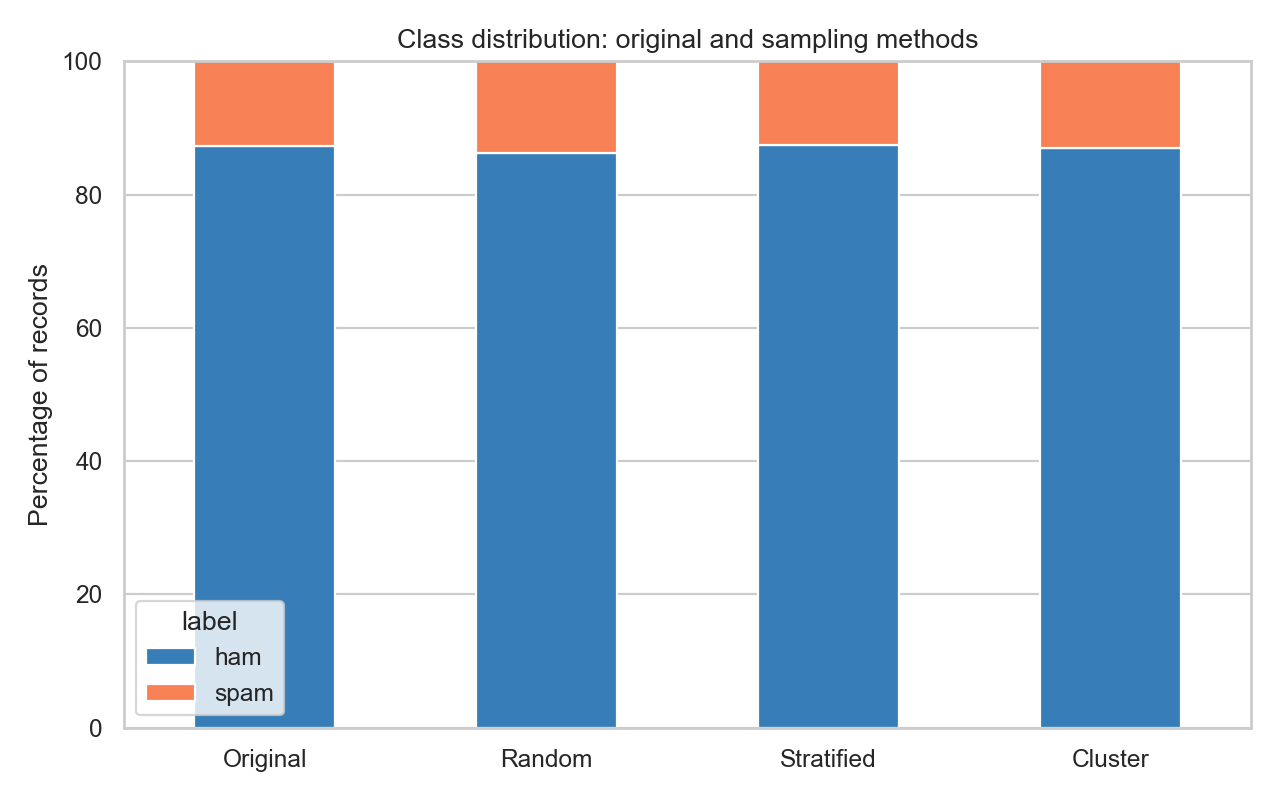

In [10]:
# Random sampling: equally likely SMS records; stratified: maintain label ratios; cluster: sample entire groups of records.
n=min(1000,len(df))
random_sample=df.sample(n=n,random_state=SEED)
strat_train,_=train_test_split(df,train_size=n,stratify=df['label'],random_state=SEED)
# Genuine cluster sampling: group by first available original record block (100 records per cluster),
# randomly choose whole blocks; natural corpus order can affect the estimates.
df['sampling_cluster']=df.index//100
rng=np.random.default_rng(SEED)
block_ids=rng.permutation(df['sampling_cluster'].unique())[:10]
cluster_sample=df[df['sampling_cluster'].isin(block_ids)]
samples={'Original':df,'Random':random_sample,'Stratified':strat_train,'Cluster':cluster_sample}
dist=pd.DataFrame({name:v['label'].value_counts(normalize=True).reindex(['ham','spam'],fill_value=0) for name,v in samples.items()}).T
print('SAMPLE SIZES:',{k:len(v) for k,v in samples.items()})
print('CLASS DISTRIBUTIONS (%):\n',(dist*100).round(2).to_string())
display((dist*100).round(2))
ax=(dist*100).plot(kind='bar',stacked=True,figsize=(8,5),color=['#377eb8','#f78154'])
ax.set(ylabel='Percentage of records',title='Class distribution: original and sampling methods',ylim=(0,100));plt.xticks(rotation=0);plt.tight_layout();plt.savefig(FIG/'sampling_distribution.png',dpi=160);plt.close()
from IPython.display import Image, display
display(Image(filename=str(FIG/'sampling_distribution.png')))


## Correlation heatmap

,char_count,word_count,unique_word_count,avg_word_length
char_count,1.000,0.979,0.959,0.190
word_count,0.979,1.000,0.975,0.054
unique_word_count,0.959,0.975,1.000,0.054
avg_word_length,0.190,0.054,0.054,1.000


CORRELATION MATRIX:
                    char_count  word_count  unique_word_count  avg_word_length
char_count              1.000       0.979              0.959            0.190
word_count              0.979       1.000              0.975            0.054
unique_word_count       0.959       0.975              1.000            0.054
avg_word_length         0.190       0.054              0.054            1.000


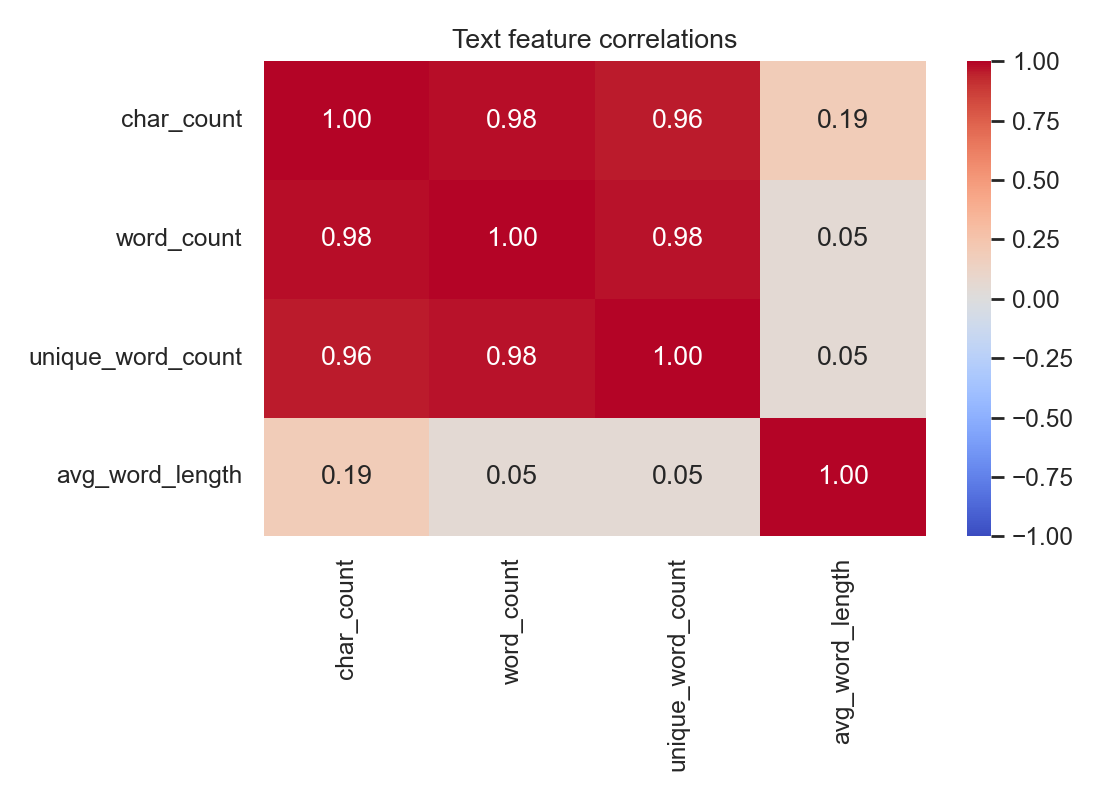

In [11]:
features=['char_count','word_count','unique_word_count','avg_word_length']
corr=df[features].corr()
display(corr.round(3))
print('CORRELATION MATRIX:\n',corr.round(3).to_string())
plt.figure(figsize=(7,5));sns.heatmap(corr,annot=True,cmap='coolwarm',vmin=-1,vmax=1,fmt='.2f');plt.title('Text feature correlations');plt.tight_layout();plt.savefig(FIG/'correlation_heatmap.png',dpi=160);plt.close()
from IPython.display import Image, display
display(Image(filename=str(FIG/'correlation_heatmap.png')))


## Token statistics and frequency comparison

TOTAL TOKENS: 82652 UNIQUE: 7742 AVERAGE WORDS/RECORD: 15.99


,word,count
0,i,2860
1,numtoken,2575
2,you,2150
3,to,2080
4,a,1325
5,the,1249
6,u,1090
7,and,930
8,in,835
9,is,800


,word,count
0,numtoken,2575
1,just,350
2,ur,322
3,gt,288
4,lt,287
5,ok,261
6,free,253
7,know,244
8,ll,237
9,like,236


TOP 20 RAW:
     word  count
       i   2860
numtoken   2575
     you   2150
      to   2080
       a   1325
     the   1249
       u   1090
     and    930
      in    835
      is    800
      me    758
      it    693
      my    692
     for    666
    your    623
    that    570
       s    565
      of    561
    have    541
    call    514
TOP 20 WITHOUT STOPWORDS:
     word  count
numtoken   2575
    just    350
      ur    322
      gt    288
      lt    287
      ok    261
    free    253
    know    244
      ll    237
    like    236
     got    234
    good    229
    come    217
     day    214
    time    211
    love    196
    want    191
    text    176
    send    171
   going    167


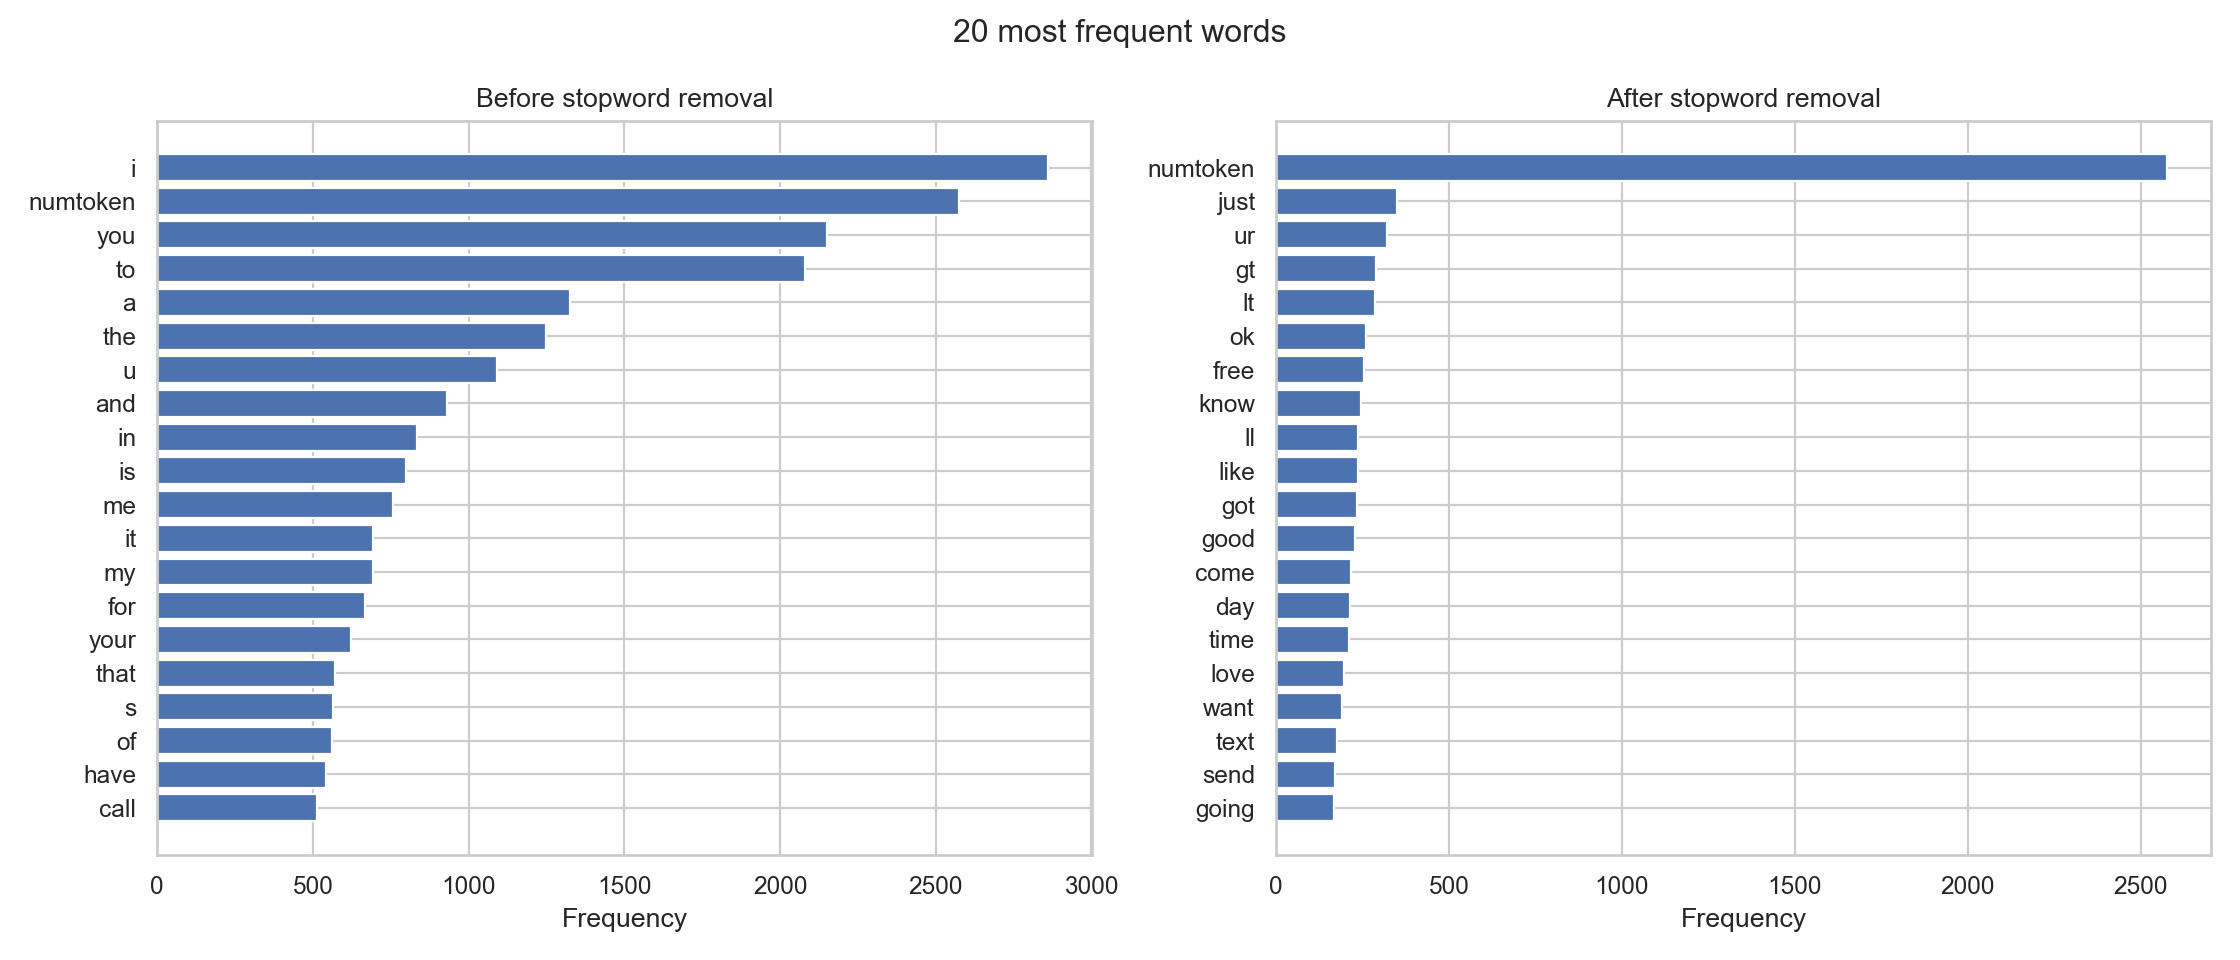

In [12]:
all_tokens=[token for tokens in df['tokens'] for token in tokens]
counts=collections.Counter(all_tokens)
filtered=collections.Counter(w for w in all_tokens if w not in ENGLISH_STOP_WORDS and len(w)>1)
print('TOTAL TOKENS:',len(all_tokens),'UNIQUE:',len(counts),'AVERAGE WORDS/RECORD:',round(df['word_count'].mean(),2))
display(pd.DataFrame(counts.most_common(20),columns=['word','count']))
display(pd.DataFrame(filtered.most_common(20),columns=['word','count']))
print('TOP 20 RAW:\n',pd.DataFrame(counts.most_common(20),columns=['word','count']).to_string(index=False))
print('TOP 20 WITHOUT STOPWORDS:\n',pd.DataFrame(filtered.most_common(20),columns=['word','count']).to_string(index=False))
fig,axes=plt.subplots(1,2,figsize=(14,6))
for ax,c,title in zip(axes,[counts,filtered],['Before stopword removal','After stopword removal']):
    top=c.most_common(20);ax.barh([x[0] for x in top][::-1],[x[1] for x in top][::-1]);ax.set_title(title);ax.set_xlabel('Frequency')
fig.suptitle('20 most frequent words');plt.tight_layout();plt.savefig(FIG/'word_frequency.png',dpi=160);plt.close()
from IPython.display import Image, display
display(Image(filename=str(FIG/'word_frequency.png')))


## Compare groups

HAM vs SPAM:
        records  average_characters  average_words
label                                            
ham       4516               70.87          14.67
spam       653              137.66          25.12


,records,average_characters,average_words
label,,,
ham,4516,70.87,14.67
spam,653,137.66,25.12


TOP 10 ham [('numtoken', 827), ('gt', 288), ('lt', 287), ('just', 282), ('ok', 256), ('ll', 233), ('got', 228), ('know', 226), ('like', 224), ('good', 217)]
TOP 10 spam [('numtoken', 1748), ('free', 197), ('txt', 138), ('ur', 119), ('stop', 116), ('mobile', 111), ('text', 108), ('claim', 96), ('reply', 96), ('urltoken', 90)]


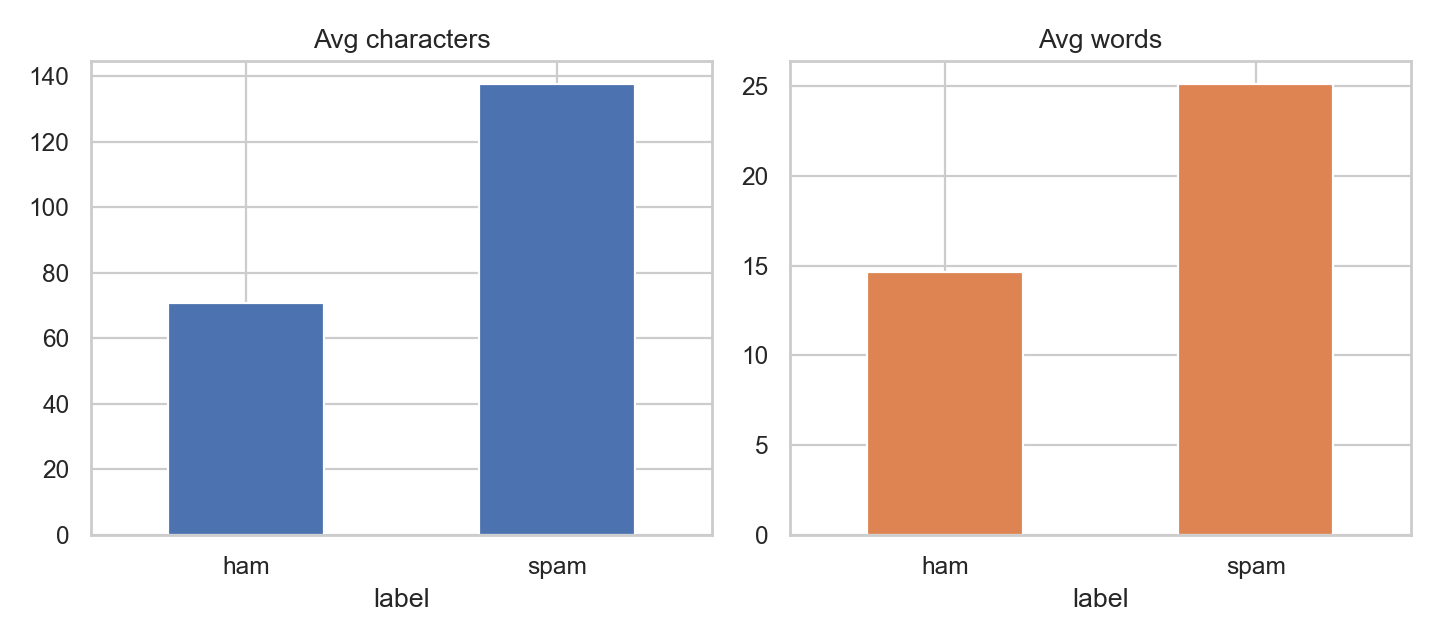

In [13]:
summary=df.groupby('label',observed=True).agg(records=('label','size'),average_characters=('char_count','mean'),average_words=('word_count','mean'))
print('HAM vs SPAM:\n',summary.round(2).to_string())
display(summary.round(2))
for label,sub in df.groupby('label'):
    words=collections.Counter(w for ts in sub['tokens'] for w in ts if w not in ENGLISH_STOP_WORDS and len(w)>1)
    print('TOP 10',label,words.most_common(10))
ax=summary[['average_characters','average_words']].plot(kind='bar',subplots=True,layout=(1,2),figsize=(9,4),legend=False,rot=0,title=['Avg characters','Avg words'])
plt.tight_layout();plt.savefig(FIG/'group_comparison.png',dpi=160);plt.close()
from IPython.display import Image, display
display(Image(filename=str(FIG/'group_comparison.png')))


## Supervised TF-IDF logistic regression

SUPERVISED RESULTS
               precision    recall  f1-score   support

         ham     0.9900    0.9911    0.9906       903
        spam     0.9385    0.9313    0.9349       131

    accuracy                         0.9836      1034
   macro avg     0.9643    0.9612    0.9627      1034
weighted avg     0.9835    0.9836    0.9835      1034
 
CONFUSION MATRIX:
 [[895   8]
 [  9 122]]


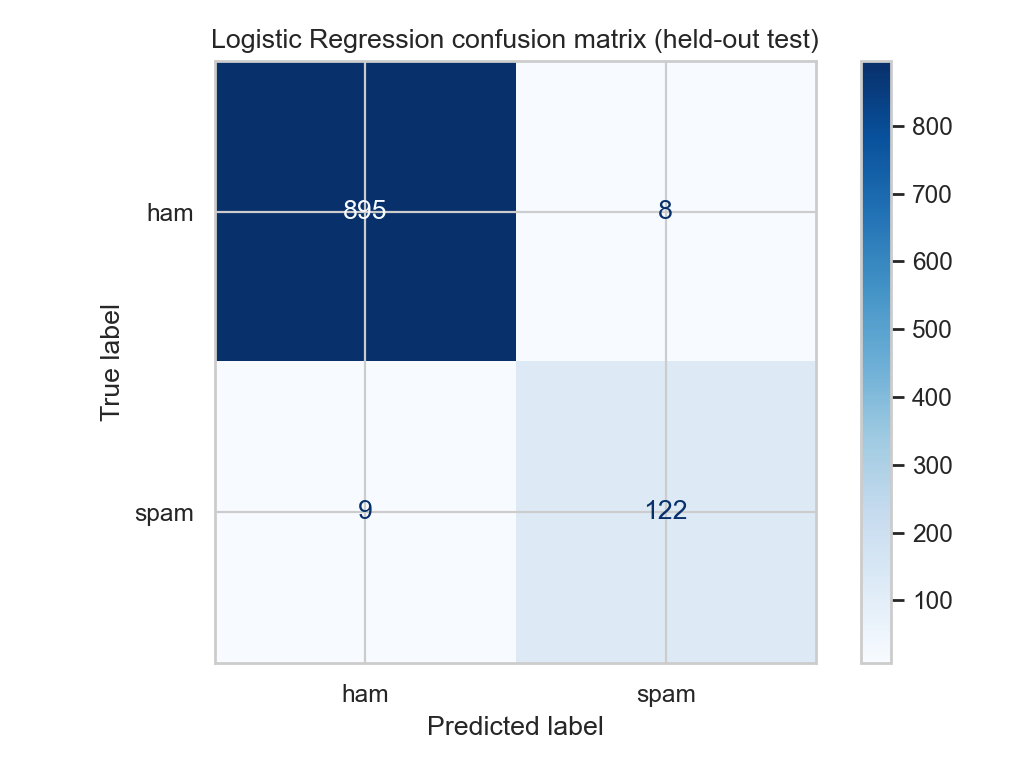

In [14]:
X_train,X_test,y_train,y_test=train_test_split(df['cleaned_text'],df['label'],test_size=.2,stratify=df['label'],random_state=SEED)
vectorizer=TfidfVectorizer(ngram_range=(1,2),min_df=2,sublinear_tf=True)
Xtr=vectorizer.fit_transform(X_train)
Xte=vectorizer.transform(X_test)
clf=LogisticRegression(max_iter=1500,class_weight='balanced',random_state=SEED)
clf.fit(Xtr,y_train);pred=clf.predict(Xte)
acc=accuracy_score(y_test,pred)
p,r,f,_=precision_recall_fscore_support(y_test,pred,average='binary',pos_label='spam',zero_division=0)
report=classification_report(y_test,pred,digits=4,zero_division=0)
cm=confusion_matrix(y_test,pred,labels=['ham','spam'])
print('SUPERVISED RESULTS\n',report,'\nCONFUSION MATRIX:\n',cm)
ConfusionMatrixDisplay(cm,display_labels=['ham','spam']).plot(cmap='Blues',values_format='d');plt.title('Logistic Regression confusion matrix (held-out test)');plt.tight_layout();plt.savefig(FIG/'confusion_matrix.png',dpi=160);plt.close()
(OUT/'model_metrics.txt').write_text(f'TF-IDF (1-2 grams, min_df=2) + balanced Logistic Regression\n80/20 stratified split; random_state={SEED}; duplicate SMS rows removed before split.\nTest size: {len(y_test)}\nAccuracy: {acc:.4f}\nSpam precision: {p:.4f}\nSpam recall: {r:.4f}\nSpam F1: {f:.4f}\n\n{report}\nConfusion matrix labels [ham,spam]:\n{cm}\nLimitation: SMS language shifts over time; dataset is historical and text-only.\n',encoding='utf-8')
from IPython.display import Image, display
display(Image(filename=str(FIG/'confusion_matrix.png')))


## Unsupervised K-Means clustering

In [15]:
# k=2 matches two broad types of messages but need not recover labels; SVD makes sparse TF-IDF tractable.
all_tfidf=TfidfVectorizer(min_df=3,max_features=3500,stop_words='english').fit_transform(df['cleaned_text'])
svd=TruncatedSVD(n_components=50,random_state=SEED)
reduced=Normalizer(copy=False).fit_transform(svd.fit_transform(all_tfidf))
k=2
km=MiniBatchKMeans(n_clusters=k,random_state=SEED,n_init=10,batch_size=512)
cluster=km.fit_predict(reduced)
df['cluster']=cluster
cluster_counts=pd.Series(cluster).value_counts().sort_index()
# Silhouette on random subsample for practical execution time.
sil=silhouette_score(reduced,cluster,sample_size=min(1000,len(df)),random_state=SEED)
ari=adjusted_rand_score(df['label_encoded'],cluster)
ct=pd.crosstab(df['cluster'],df['label'],normalize='index')
print('CLUSTER SIZES:\n',cluster_counts.to_string(),'\nSILHOUETTE:',round(sil,4),'ARI:',round(ari,4),'\nLABEL COMPOSITION:\n',ct.round(3).to_string())
lines=[f'K-Means (MiniBatchKMeans) on 50D SVD-normalized word TF-IDF; k={k} (two known broad SMS types; unsupervised).',f'Sampled silhouette score (up to 1000 rows): {sil:.4f}',f'Adjusted Rand Index vs labels: {ari:.4f}','Cluster sizes: '+str(cluster_counts.to_dict()),'Proportion of labels within each cluster:\n'+ct.round(3).to_string()]
for cluster_id in range(k):
    sub=df[df['cluster']==cluster_id]
    top=collections.Counter(w for tokens in sub['tokens'] for w in tokens if w not in ENGLISH_STOP_WORDS and len(w)>2).most_common(12)
    lines.append(f'Cluster {cluster_id} top terms by raw frequency: {top}')
    lines.append(f'Interpretation: cluster {cluster_id} has {ct.loc[cluster_id].idxmax()} as its largest known-label group ({ct.loc[cluster_id].max():.1%}); inspect terms for recurring SMS themes; labels and cluster IDs are not equivalent.')
(OUT/'cluster_summary.txt').write_text('\n'.join(lines)+'\n',encoding='utf-8')
print('\n'.join(lines))
# Re-save with cluster but not temporary list tokens or sample-cluster helper.
df.drop(columns=['tokens','sampling_cluster']).to_csv(ROOT/'cleaned_data.csv',index=False)

d:\Downloads\Anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "d:\Downloads\Anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "d:\Downloads\Anaconda\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "d:\Downloads\Anaconda\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

CLUSTER SIZES:
 0    1037
1    4132 
SILHOUETTE: 0.0701 ARI: 0.5567 
LABEL COMPOSITION:
 label      ham   spam
cluster              
0        0.430  0.570
1        0.985  0.015
K-Means (MiniBatchKMeans) on 50D SVD-normalized word TF-IDF; k=2 (two known broad SMS types; unsupervised).
Sampled silhouette score (up to 1000 rows): 0.0701
Adjusted Rand Index vs labels: 0.5567
Cluster sizes: {0: 1037, 1: 4132}
Proportion of labels within each cluster:
label      ham   spam
cluster              
0        0.430  0.570
1        0.985  0.015
Cluster 0 top terms by raw frequency: [('numtoken', 2436), ('free', 194), ('txt', 139), ('stop', 110), ('mobile', 103), ('claim', 94), ('text', 93), ('reply', 91), ('prize', 82), ('urltoken', 80), ('just', 73), ('cash', 64)]
Interpretation: cluster 0 has spam as its largest known-label group (57.0%); inspect terms for recurring SMS themes; labels and cluster IDs are not equivalent.
Cluster 1 top terms by raw frequency: [('just', 277), ('know', 222), ('good',

## Evidence-based insights

In [16]:
for label in ['ham','spam']:
    print(label,'records:',(df['label']==label).sum())
print('Insight 1: class balance: ham %.1f%% vs spam %.1f%%; imbalance suggests stratified evaluation.'%(100*(df['label']=='ham').mean(),100*(df['label']=='spam').mean()))
print('Insight 2: mean chars: ham %.1f, spam %.1f; message length carries signal.'%(summary.loc['ham','average_characters'],summary.loc['spam','average_characters']))
print('Insight 3: word/unique-word correlation %.3f; both represent related aspects of verbosity.'%corr.loc['word_count','unique_word_count'])
print('Insight 4: precision %.3f and recall %.3f for spam; classification performance depends on both false alarms and missed spam.'%(p,r))
print('Insight 5: cluster silhouette %.3f and ARI %.3f; textual topics need not correspond to spam labels.'%(sil,ari))
print('Correlation does not imply causation: longer SMS can correlate with word count without one feature causally creating the other; both are derived from the same text.')

ham records: 4516
spam records: 653
Insight 1: class balance: ham 87.4% vs spam 12.6%; imbalance suggests stratified evaluation.
Insight 2: mean chars: ham 70.9, spam 137.7; message length carries signal.
Insight 3: word/unique-word correlation 0.975; both represent related aspects of verbosity.
Insight 4: precision 0.938 and recall 0.931 for spam; classification performance depends on both false alarms and missed spam.
Insight 5: cluster silhouette 0.070 and ARI 0.557; textual topics need not correspond to spam labels.
Correlation does not imply causation: longer SMS can correlate with word count without one feature causally creating the other; both are derived from the same text.
